<a href="https://colab.research.google.com/github/cvoidelo/EPB_omicas_aplicadas_ao_cancer_2026/blob/main/EPB_transcriptoma_espacial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introdução à Análise de Dados Ômicos no Câncer: Transcriptômica - transcriptoma espacial

Nas aulas anteriores vimos o *bulk* RNA-seq, que mede a média de um tecido inteiro, e o scRNA-seq, que mede cada célula mas retira a célula do lugar onde ela estava. O transcriptoma espacial mede a expressão gênica **sem perder a posição no tecido**. Neste notebook vamos abrir um dado real de câncer de mama, entender do que ele é feito e dar os primeiros passos de análise com o **Seurat**.

### Módulos do Workshop

| Módulo | Descrição da Etapa | Ferramentas Principais |
|---|---|---|
| **Conceitos** | O que é transcriptoma espacial, Visium e Visium HD. | - |
| **1. Setup** | Instalação dos pacotes. | Seurat |
| **2. Download** | Baixar uma amostra pública de câncer de mama. | R base |
| **3. Anatomia do dado** | Imagem da lâmina, matriz de expressão e coordenadas x/y. | Seurat, ggplot2 |
| **4. Como o dado é guardado** | Objeto Seurat e formato HDF5. | Seurat |
| **5. Controle de Qualidade** | Contagens e genes detectados no tecido. | Seurat |
| **6. Processamento** | Normalização, PCA, clusters e UMAP. | Seurat |
| **7. Visualização** | Clusters e genes sobre o tecido. | Seurat |
| **8. Deconvolução didática** | Estimar a mistura de tipos celulares em cada spot. | nnls |

### Roteiro para 20 minutos

| Tempo | Conteúdo |
|---|---|
| **Antes da aula** | Abrir o Colab e rodar as Etapas 1 e 2 |
| 0 a 4 min | O que é transcriptoma espacial e plataformas |
| 4 a 9 min | Etapa 3: anatomia do dado |
| 9 a 12 min | Etapa 4: objeto Seurat e HDF5 |
| 12 a 16 min | Etapas 5, 6 e 7: QC, clusters e genes no tecido |
| 16 a 19 min | Etapa 8: deconvolução didática |
| 19 a 20 min | Fechamento |

Se a aula atrasar, pule o código da Etapa 8 e mantenha só a explicação.

### Como rodar no Google Colab

1. Clique no botão **Open in Colab**, no topo deste notebook.
2. Confira o ambiente em **Ambiente de execução > Alterar o tipo de ambiente de execução**: a linguagem deve ser **R**. Não é preciso GPU.
3. Rode as células **de cima para baixo**, uma de cada vez, com `Shift + Enter`.
4. Rode as **Etapas 1 e 2 antes da aula**: são as únicas que dependem da internet e as mais demoradas.

Se o ambiente do Colab reiniciar, os pacotes e os dados são apagados e é preciso rodar tudo de novo a partir da Etapa 1.

---
# Parte 1: Conceitos

## O que é transcriptoma espacial?

Imagine que um órgão é uma escultura de LEGO e que cada peça é uma célula, com a cor indicando o tipo celular.

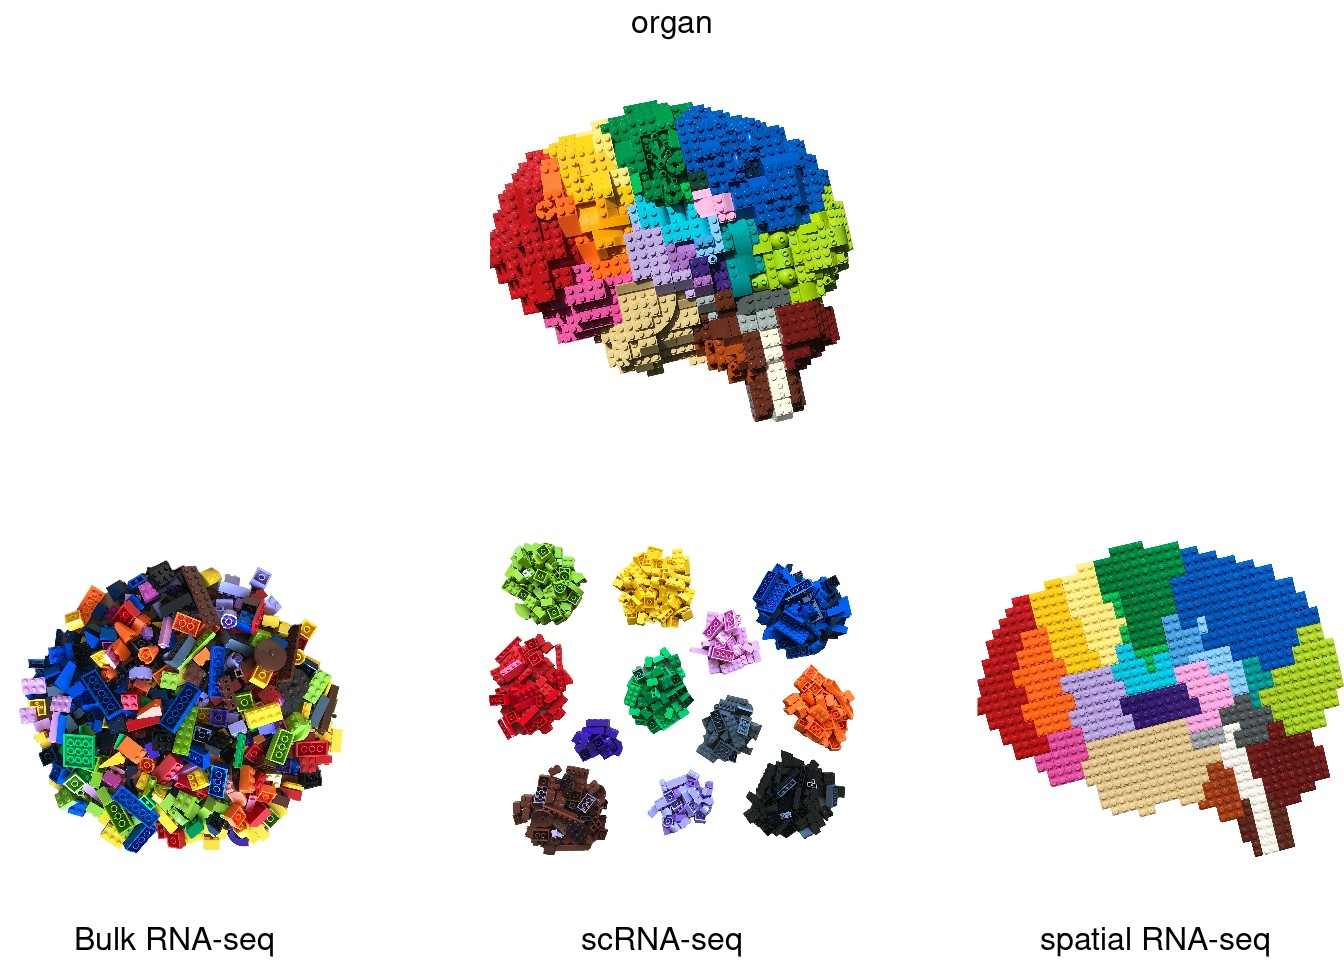

* **Bulk RNA-seq:** todas as peças vão para o mesmo monte. Sabemos quais cores existem e em que quantidade, mas não conseguimos separar a contribuição de cada peça.
* **scRNA-seq:** as peças são separadas por cor. Descobrimos os tipos celulares, inclusive os raros, mas perdemos a informação de onde cada peça estava.
* **Spatial RNA-seq:** a escultura continua montada. Medimos a expressão gênica e sabemos **onde** ela acontece.

### Por que isso importa no câncer?

Um tumor é um ecossistema organizado. O comportamento de uma célula depende de quem está ao lado dela, e várias perguntas importantes em oncologia são perguntas sobre **lugar**:

* Os linfócitos estão dentro do tumor ou parados na borda, excluídos pelo estroma?
* O que muda na interface entre o tumor e o tecido vizinho?
* Existem regiões do mesmo tumor com programas transcricionais diferentes?

A dissociação usada no scRNA-seq apaga essas relações. O dado espacial preserva.

## Plataformas da 10x Genomics: Visium e Visium HD

As duas plataformas seguem a mesma ideia: o tecido é colocado sobre uma lâmina com sondas que carregam um **código de barras espacial**. Cada código corresponde a uma posição conhecida na lâmina. Depois do sequenciamento, o código de barras diz de onde veio cada transcrito.

A diferença entre elas é o tamanho da unidade que está sendo medida.

| | **Visium v1/v2** | **Visium HD** |
|---|---|---|
| **Resolução** | Baixa | Alta |
| **Unidade do dado** | Spot circular de 55 µm, com 100 µm entre centros | Quadrados de 2 µm, agregados em *bins* de 8 ou 16 µm |
| **Arranjo na lâmina** | ~5.000 spots, com lacunas entre eles | Mais de 11 milhões de quadrados, sem lacunas |
| **Células por unidade** | ~2 a 10 | ~1 no *bin* de 8 µm |
| **Leitura no Seurat** | `Load10X_Spatial()` | `Load10X_Spatial(bin.size = c(8, 16))` |

### Baixa resolução: Visium v1/v2

Cada spot captura o RNA de várias células vizinhas, então **um spot não é uma célula**: ele é uma pequena mistura. E como existem lacunas entre os spots, parte do tecido não é medida. Em troca, o dado é leve, com alguns milhares de spots, e a análise se parece muito com a de single-cell. É uma boa escolha para mapear regiões do tecido e grandes compartimentos, como tumor, estroma e infiltrado imune.

### Alta resolução: Visium HD

A lâmina é um tapete contínuo de quadrados de 2 µm. Como cada quadrado isolado tem poucas contagens, o Space Ranger agrega os quadrados em *bins* maiores, e o *bin* de 8 µm é o mais usado por chegar perto da escala de uma célula. É a escolha quando a pergunta exige olhar vizinhanças celulares, como a interface entre tumor e linfócitos.

O preço é o tamanho do dado. Uma única lâmina gera centenas de milhares de *bins*: o pacote público de Visium HD de câncer de cólon tem **15,9 GB**, o que não cabe em uma sessão do Colab. Além disso, a leitura precisa do pacote `arrow`, e o Seurat recomenda uma estratégia de amostragem (`SketchData`). Por isso, **nesta aula o Visium HD fica na teoria** e a prática usa o Visium. Os conceitos são os mesmos: uma imagem, uma matriz e coordenadas.

---
# Parte 2: Prática com Visium

## Etapa 1: Setup

**O que vamos fazer:** instalar os pacotes. **Rode antes da aula.**

**Por quê desse jeito:** instalar o Seurat a partir do código-fonte é lento, porque tudo precisa ser compilado. Aqui usamos **binários** do Posit Package Manager, que já vêm compilados para o Linux do Colab. Também instalamos a biblioteca de sistema `libglpk`: sem ela, o pacote `igraph` não carrega e o Seurat falha.

In [ ]:
inicio <- Sys.time()
pacotes <- c("Seurat", "patchwork", "ggplot2", "dplyr", "nnls")
faltando <- function() pacotes[!sapply(pacotes, requireNamespace, quietly = TRUE)]

if (length(faltando()) > 0) {
  # Biblioteca de sistema exigida pelo igraph (dependência do Seurat)
  system("apt-get update -qq && apt-get install -y -qq libglpk-dev")

  # Descobre a versão do Ubuntu para pedir os binários certos
  sistema <- readLines("/etc/os-release")
  ubuntu <- sub("VERSION_CODENAME=", "", grep("^VERSION_CODENAME=", sistema, value = TRUE))

  options(
    repos = c(CRAN = paste0("https://packagemanager.posit.co/cran/__linux__/", ubuntu, "/latest")),
    HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(),
                            paste(getRversion(), R.version["platform"], R.version["arch"], R.version["os"])),
    Ncpus = parallel::detectCores(),
    timeout = 600
  )
  install.packages(faltando())

  # Plano B: se algum binário falhar, compila a partir do CRAN (bem mais lento)
  if (length(faltando()) > 0) install.packages(faltando(), repos = "https://cloud.r-project.org")
}

stopifnot("Algum pacote não instalou. Veja as mensagens acima." = length(faltando()) == 0)

library(Seurat)
library(ggplot2)
library(patchwork)
library(dplyr)

cat("Pronto em", round(difftime(Sys.time(), inicio, units = "mins"), 1), "minutos. Seurat", as.character(packageVersion("Seurat")), "\n")

**Como ler o resultado:** a última linha deve mostrar `Pronto em ... minutos` e a versão do Seurat. Se aparecer `Algum pacote não instalou`, procure nas mensagens acima o nome do pacote que falhou.

## Etapa 2: Download dos dados

**O que vamos fazer:** baixar uma amostra pública de **carcinoma ductal invasivo de mama** (tecido congelado, estágio IIA, ER+, PR−, HER2+), disponibilizada pela 10x Genomics sob licença CC BY 4.0. São cerca de 88 MB. **Rode antes da aula.**

**Onde encontrar outros dados:** esta amostra vem do [catálogo de datasets da 10x Genomics](https://www.10xgenomics.com/datasets?sort=publishedAt+DESC), que reúne conjuntos públicos de vários tecidos e plataformas.

In [ ]:
options(timeout = 600)
base <- "https://cf.10xgenomics.com/samples/spatial-exp/1.1.0/V1_Breast_Cancer_Block_A_Section_1/V1_Breast_Cancer_Block_A_Section_1"
dir.create("dados", showWarnings = FALSE)

for (arquivo in c("filtered_feature_bc_matrix.tar.gz", "spatial.tar.gz")) {
  destino <- file.path("dados", arquivo)
  if (!file.exists(destino)) download.file(paste0(base, "_", arquivo), destino, mode = "wb")
  untar(destino, exdir = "dados")
}

list.files("dados", recursive = TRUE)

**Como ler o resultado:** o Space Ranger, software da 10x que processa o dado bruto, entrega duas pastas.

| Arquivo | O que guarda |
|---|---|
| `filtered_feature_bc_matrix/barcodes.tsv.gz` | Os códigos de barras dos spots (colunas da matriz) |
| `filtered_feature_bc_matrix/features.tsv.gz` | Os genes (linhas da matriz) |
| `filtered_feature_bc_matrix/matrix.mtx.gz` | As contagens, em formato esparso |
| `spatial/tissue_hires_image.png` | Foto do tecido em alta resolução |
| `spatial/tissue_lowres_image.png` | Foto do tecido em baixa resolução |
| `spatial/tissue_positions_list.csv` | A posição de cada spot na lâmina e na imagem |
| `spatial/scalefactors_json.json` | Os fatores que convertem pixels entre as imagens |
| `spatial/aligned_fiducials.jpg` | Imagem de conferência do alinhamento com a moldura da lâmina |
| `spatial/detected_tissue_image.jpg` | Imagem de conferência dos spots detectados sob o tecido |

A primeira pasta é igual à que vimos na aula de single-cell. A novidade está na pasta `spatial/`.

## Etapa 3: Anatomia do dado

Um dado espacial é feito de **três peças**, ligadas pelo código de barras de cada spot:

1. **Imagem:** o que o tecido é, visto ao microscópio.
2. **Matriz de expressão:** quanto de cada gene foi medido em cada spot.
3. **Coordenadas:** onde cada spot está.

Antes de usar qualquer função pronta, vamos abrir cada peça com as mãos.

### 3a. A imagem da lâmina

**O que vamos fazer:** abrir a foto do tecido corado com hematoxilina e eosina (H&E). Para o R, a imagem é apenas um *array* de números: altura × largura × canais de cor.

In [ ]:
imagem <- png::readPNG("dados/spatial/tissue_hires_image.png")
dim(imagem)

options(repr.plot.width = 7, repr.plot.height = 7)
plot(NA, xlim = c(0, ncol(imagem)), ylim = c(nrow(imagem), 0), asp = 1,
     axes = FALSE, xlab = "", ylab = "")
rasterImage(imagem, 0, nrow(imagem), ncol(imagem), 0)

**Como ler o resultado:** `dim(imagem)` mostra a altura, a largura e o número de canais. Na foto, a hematoxilina cora os núcleos em roxo e a eosina cora citoplasma e matriz extracelular em rosa. Regiões muito densas em núcleos e regiões mais rosadas e fibrosas costumam ter composições celulares diferentes. Guarde essa imagem na memória: vamos compará-la com os resultados das próximas etapas.

### 3b. A matriz de expressão

**O que vamos fazer:** ler a matriz, que tem o mesmo formato do single-cell. A diferença é o significado das colunas: aqui cada coluna é **um spot**, não uma célula.

In [ ]:
contagens <- Read10X("dados/filtered_feature_bc_matrix")

cat("Genes:", nrow(contagens), "\nSpots:", ncol(contagens), "\n\n")

# Um recorte da matriz: genes nas linhas, spots nas colunas
genes_exemplo <- intersect(c("EPCAM", "ERBB2", "COL1A1", "PTPRC"), rownames(contagens))
as.matrix(contagens[genes_exemplo, 1:4])

# Quantos valores da matriz são zero?
nao_zero <- Matrix::nnzero(contagens)
cat("Valores iguais a zero:", round(100 * (1 - nao_zero / prod(dim(contagens))), 1), "%\n")

**Como ler o resultado:** esta amostra tem 36.601 genes e 3.798 spots sob o tecido. Cada número do recorte é a quantidade de moléculas de RNA daquele gene em um spot. A maior parte da matriz é zero, e é por isso que ela é guardada em **formato esparso**, que registra apenas os valores diferentes de zero.

### 3c. As coordenadas x e y

**O que vamos fazer:** abrir a tabela de posições. Neste arquivo não há cabeçalho, então damos os nomes das colunas.

In [ ]:
posicoes <- read.csv("dados/spatial/tissue_positions_list.csv", header = FALSE,
                     col.names = c("barcode", "in_tissue", "array_row", "array_col",
                                   "pxl_row_in_fullres", "pxl_col_in_fullres"))
head(posicoes)

# Quantos spots existem na lâmina e quantos caíram sobre o tecido?
table(in_tissue = posicoes$in_tissue)

# Fatores de escala entre a imagem original e as imagens salvas
escala <- jsonlite::fromJSON("dados/spatial/scalefactors_json.json")
str(escala)

options(repr.plot.width = 7, repr.plot.height = 5)
ggplot(posicoes, aes(array_col, -array_row, color = factor(in_tissue))) +
  geom_point(size = 0.8) +
  coord_fixed(ratio = sqrt(3)) +
  scale_color_manual(values = c("0" = "grey80", "1" = "firebrick"),
                     labels = c("fora do tecido", "sob o tecido"), name = NULL) +
  labs(title = "Os spots da área de captura") +
  theme_void()

**Como ler o resultado:** cada linha da tabela é um spot, com dois sistemas de coordenadas.

| Coluna | Significado |
|---|---|
| `barcode` | O código de barras, que liga esta tabela à matriz |
| `in_tissue` | `1` se o spot está sob o tecido, `0` se não |
| `array_row`, `array_col` | Posição na **grade** da lâmina (linha e coluna) |
| `pxl_row_in_fullres` | Posição em **pixels** na imagem original: é o **y** |
| `pxl_col_in_fullres` | Posição em **pixels** na imagem original: é o **x** |

A imagem original é muito grande, então a pasta `spatial/` guarda versões reduzidas. Para desenhar um spot na imagem `hires`, multiplicamos o pixel por `tissue_hires_scalef`. O gráfico mostra a grade hexagonal completa, com 4.992 spots, dos quais 3.798 caíram sob o tecido. Só estes aparecem na matriz filtrada.

### 3d. Juntando as três peças

**O que vamos fazer:** seguir um único spot pelas três fontes e depois desenhar um gene sobre a imagem, sem usar nenhuma função espacial do Seurat.

In [ ]:
# Um spot qualquer: o código de barras é a chave que liga tudo
spot <- colnames(contagens)[1]
cat("Spot escolhido:", spot, "\n\n")

cat("Na matriz (contagens):\n")
print(contagens[genes_exemplo, spot])

cat("\nNa tabela de coordenadas:\n")
print(posicoes[posicoes$barcode == spot, ])

cat("\nNa imagem hires (pixels):",
    "x =", round(posicoes$pxl_col_in_fullres[posicoes$barcode == spot] * escala$tissue_hires_scalef),
    "| y =", round(posicoes$pxl_row_in_fullres[posicoes$barcode == spot] * escala$tissue_hires_scalef), "\n")

In [ ]:
gene <- "EPCAM"

# Ordena as coordenadas na mesma ordem das colunas da matriz
tecido <- posicoes[match(colnames(contagens), posicoes$barcode), ]
tecido$x <- tecido$pxl_col_in_fullres * escala$tissue_hires_scalef
tecido$y <- tecido$pxl_row_in_fullres * escala$tissue_hires_scalef
tecido$expressao <- log1p(as.numeric(contagens[gene, ]))

options(repr.plot.width = 8, repr.plot.height = 7)
ggplot(tecido, aes(x, -y, color = expressao)) +
  annotation_raster(imagem, xmin = 0, xmax = ncol(imagem), ymin = -nrow(imagem), ymax = 0) +
  geom_point(size = 1.2) +
  scale_color_viridis_c(name = "log(1 + contagem)") +
  coord_fixed(xlim = c(0, ncol(imagem)), ylim = c(-nrow(imagem), 0), expand = FALSE) +
  labs(title = paste("Expressão de", gene, "sobre o tecido")) +
  theme_void()

**Como ler o resultado:** imagem, matriz e coordenadas viraram um único gráfico. Cada ponto é um spot, colocado na posição dada pela tabela e colorido pelo valor da matriz. `EPCAM` é um marcador de células epiteliais, então os spots mais claros indicam regiões ricas em epitélio. Compare com a foto da Etapa 3a. O `y` entra negativo porque, em imagens, o eixo vertical cresce de cima para baixo.

Esse é o coração do transcriptoma espacial. Tudo o que as funções do Seurat fazem a seguir parte destas três peças.

## Etapa 4: Como o dado é guardado

### 4a. O objeto Seurat

**O que vamos fazer:** colocar as três peças em uma única caixa, o objeto Seurat. É o mesmo tipo de objeto da aula de single-cell, com uma gaveta a mais: `images`.

| Parte do objeto | O que guarda | Como acessar |
|---|---|---|
| **assays** | As matrizes, separadas por tipo de dado | `mama[["Spatial"]]` |
| **layers** | Versões da matriz dentro do assay: `counts`, `data`, `scale.data` | `mama[["Spatial"]]$counts` |
| **meta.data** | Uma linha por spot: QC, clusters, anotações | `mama[[]]` |
| **images** | Imagem, coordenadas e fatores de escala | `mama[["slice1"]]` |
| **reductions** | PCA e UMAP, criados na Etapa 6 | `mama[["pca"]]` |

In [ ]:
# Peça 2: a matriz vira o assay "Spatial"
mama <- CreateSeuratObject(counts = contagens, assay = "Spatial", project = "mama_visium")

# Peças 1 e 3: a imagem e as coordenadas entram juntas
imagem_seurat <- Read10X_Image("dados/spatial", assay = "Spatial", slice = "slice1")
mama[["slice1"]] <- imagem_seurat[Cells(mama)]

mama

In [ ]:
cat("Assays:", Assays(mama), "\n")
cat("Layers:", Layers(mama[["Spatial"]]), "\n")
cat("Imagens:", Images(mama), "\n\n")

cat("meta.data, uma linha por spot:\n")
print(head(mama[[]], 3))

cat("\nCoordenadas guardadas no objeto:\n")
print(head(GetTissueCoordinates(mama), 3))

**Como ler o resultado:** o objeto tem 3.798 amostras, que são os spots, embora o Seurat os trate como células. Compare com o objeto da aula de single-cell: o assay agora se chama `Spatial`, as colunas de QC viram `nCount_Spatial` e `nFeature_Spatial`, e existe uma imagem chamada `slice1`.

**Atalho:** no dia a dia, tudo isso se resume a uma linha, que lê o arquivo `.h5` da próxima seção e exige o pacote `hdf5r`:

```r
mama <- Load10X_Spatial("pasta_do_space_ranger")
```

Neste notebook montamos o objeto peça por peça por dois motivos: para enxergar o que há dentro dele, e porque o formato de pasta dispensa o `hdf5r`, que é uma dependência a menos no Colab.

Para salvar o objeto, usamos `saveRDS(mama, "mama.rds")`. O `.rds` é um formato próprio do R, que outras linguagens não leem diretamente.

### 4b. O formato HDF5

Além da pasta com três arquivos, a 10x também distribui a matriz em um arquivo único: `filtered_feature_bc_matrix.h5`. A extensão `.h5` indica **HDF5** (*Hierarchical Data Format*, versão 5), um formato feito para guardar grandes volumes de dados científicos.

A melhor forma de imaginar o HDF5 é como **um sistema de arquivos dentro de um arquivo**:

* **Grupos** funcionam como pastas.
* **Datasets** funcionam como arquivos: são as tabelas de números ou de texto.
* **Atributos** são pequenas etiquetas de metadados presas a grupos e datasets.

A grande vantagem é a **leitura parcial**: o programa pode buscar só um pedaço do arquivo, sem carregar tudo na memória.

Esta é a estrutura real do `.h5` da nossa amostra, com o tamanho de cada dataset:

```
/matrix                      grupo
├── barcodes                 3.798 códigos de barras
├── data                     21.352.329 contagens diferentes de zero
├── indices                  21.352.329 números de linha (qual gene)
├── indptr                   3.799 ponteiros (onde começa cada spot)
├── shape                    2 valores: número de genes e de spots
└── features                 grupo
    ├── id                   36.601 identificadores Ensembl
    ├── name                 36.601 símbolos de genes
    ├── feature_type         36.601 tipos de medida
    ├── genome               36.601 genomas de referência
    └── _all_tag_keys        1 lista de metadados
```

Repare que a matriz não está guardada como uma tabela. Ela é a **matriz esparsa** da Etapa 3b, dividida em três listas:

* `data`: só os valores diferentes de zero;
* `indices`: a linha, ou seja, o gene de cada valor;
* `indptr`: em que posição de `data` começa cada spot. Por isso tem 3.799 elementos, um a mais que o número de spots.

São cerca de 21 milhões de valores guardados, em vez dos 139 milhões de posições da matriz completa.

**Cuidado:** HDF5 é o contêiner, não o conteúdo. Dois arquivos HDF5 podem ter organizações internas totalmente diferentes. O `.h5` da 10x e o `.h5ad` do Python, por exemplo, usam o mesmo formato de base, mas não são intercambiáveis.

## Etapa 5: Controle de Qualidade

**O que vamos fazer:** olhar as métricas de qualidade **sobre o tecido**.

**O que muda em relação ao single-cell:**

* **Não há doublets.** Um spot já é uma mistura de células por natureza.
* **Não há limiar universal.** Na aula de single-cell removemos células com poucos genes porque provavelmente eram gotas vazias. Aqui, um spot com poucas contagens pode ser dano técnico, mas também pode ser biologia, como uma região pobre em células.
* **A posição ajuda a decidir.** Um problema técnico costuma aparecer em bordas ou dobras do tecido. Um padrão que acompanha a histologia tende a ser biológico.

Por isso, não vamos filtrar spots nesta aula. O trabalho de Bhuva et al. (2024) mostra que o número de contagens por spot acompanha a estrutura do tecido.

In [ ]:
print(summary(mama$nCount_Spatial))
print(summary(mama$nFeature_Spatial))

options(repr.plot.width = 11, repr.plot.height = 5.5)
SpatialFeaturePlot(mama, features = c("nCount_Spatial", "nFeature_Spatial")) &
  theme(legend.position = "right")

**Como ler o resultado:** `nCount_Spatial` é o total de moléculas por spot e `nFeature_Spatial` é o número de genes detectados. Compare os mapas com a foto da Etapa 3a. Se as regiões com mais contagens coincidem com as regiões de maior densidade celular, o sinal provavelmente é biológico.

## Etapa 6: Processamento

**O que vamos fazer:** repetir o pipeline da aula de single-cell. Como a matriz tem o mesmo formato, as funções são as mesmas. A única diferença é que aqui agrupamos **spots**, não células.

1. `NormalizeData`: corrige a diferença de contagens entre spots.
2. `FindVariableFeatures`: escolhe os 2.000 genes mais variáveis.
3. `ScaleData`: centraliza e padroniza cada gene.
4. `RunPCA`: resume os genes em componentes principais.
5. `FindNeighbors` e `FindClusters`: agrupam spots com perfis parecidos.
6. `RunUMAP`: projeta os spots em duas dimensões.

**Nota:** a vignette espacial do Seurat usa `SCTransform` no lugar dos passos 1 a 3. Usamos `LogNormalize` para manter a continuidade com a aula anterior e evitar dependências extras. Vale lembrar que os dois métodos corrigem o tamanho da biblioteca, o que pode remover parte do sinal biológico visto na Etapa 5.

In [ ]:
mama <- NormalizeData(mama, normalization.method = "LogNormalize", scale.factor = 10000)
mama <- FindVariableFeatures(mama, selection.method = "vst", nfeatures = 2000)
mama <- ScaleData(mama)
mama <- RunPCA(mama, features = VariableFeatures(object = mama), verbose = FALSE)
mama <- FindNeighbors(mama, dims = 1:20)
mama <- FindClusters(mama, resolution = 0.5)
mama <- RunUMAP(mama, dims = 1:20)

mama

**Como ler o resultado:** a mensagem do `FindClusters` informa quantos grupos foram encontrados, e `mama` agora lista as reduções `pca` e `umap`. Atenção: em nenhum momento o algoritmo usou as coordenadas. Os clusters vieram **apenas da expressão**.

## Etapa 7: Visualização

**O que vamos fazer:** colocar lado a lado o UMAP, que é o espaço da expressão, e o tecido, que é o espaço físico.

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 6)
p1 <- DimPlot(mama, reduction = "umap", label = TRUE) + ggtitle("Espaço da expressão (UMAP)")
p2 <- SpatialDimPlot(mama, label = TRUE, label.size = 3) + ggtitle("Espaço físico (tecido)")
p1 + p2

**Como ler o resultado:** as cores são as mesmas nos dois gráficos. Como o algoritmo não conhecia as coordenadas, é um bom sinal quando um cluster forma uma região contínua no tecido: isso sugere um compartimento real. Compare as regiões com a foto da Etapa 3a.

**O que vamos fazer agora:** ver genes conhecidos sobre o tecido.

| Gene | Marca | Por que olhar |
|---|---|---|
| `EPCAM` | Células epiteliais | Inclui as células tumorais deste carcinoma |
| `ERBB2` | HER2 | Esta amostra é HER2+ |
| `COL1A1` | Fibroblastos e matriz | Estroma |
| `PTPRC` | CD45, leucócitos | Infiltrado imune |

In [ ]:
genes <- intersect(c("EPCAM", "ERBB2", "COL1A1", "PTPRC"), rownames(mama))

options(repr.plot.width = 14, repr.plot.height = 4.5)
SpatialFeaturePlot(mama, features = genes, ncol = 4, alpha = c(0.1, 1))

**Como ler o resultado:** o argumento `alpha` deixa os spots de baixa expressão quase transparentes, revelando a imagem por baixo. Perguntas para discutir: `EPCAM` e `ERBB2` ocupam as mesmas regiões? `COL1A1` aparece onde `EPCAM` está ausente? `PTPRC` está misturado ao epitélio ou concentrado em certas regiões? Essas são exatamente as perguntas que o single-cell não consegue responder.

## Etapa 8: Deconvolução didática

### Por que a deconvolução é importante?

No Visium, cada spot contém várias células. Isso muda a interpretação de tudo o que fizemos: **um cluster de spots não é um tipo celular, é um tipo de mistura**. Se um spot expressa `EPCAM` e `PTPRC`, ele tem células tumorais e imunes juntas, e o cluster sozinho não diz em que proporção.

A **deconvolução** tenta responder: *de que tipos celulares este spot é feito?* É uma etapa central na análise de Visium.

### O modelo

Vamos usar a versão mais simples possível. A expressão de um spot é aproximada por uma soma ponderada de perfis:

$$\text{expressão do spot} \approx w_1 \cdot \text{perfil}_{\text{tumor}} + w_2 \cdot \text{perfil}_{\text{estroma}} + w_3 \cdot \text{perfil}_{\text{imune}}$$

Os pesos $w$ são estimados por **mínimos quadrados não negativos** (NNLS), uma regressão em que os pesos não podem ser negativos, porque não existe contribuição negativa de um tipo celular.

### Os passos

1. **Criar os perfis:** para cada tipo, escolhemos os spots com o sinal mais forte e exclusivo de seus marcadores e calculamos a média de expressão deles.
2. **Usar escala linear:** o modelo soma expressões, então desfazemos o log. Em escala log, a soma de duas populações não faz sentido.
3. **Tirar os marcadores da regressão:** eles foram usados para escolher os spots, e mantê-los tornaria o resultado circular.
4. **Resolver um NNLS por spot** e transformar os pesos em frações que somam 1.

In [ ]:
# 1. Marcadores canônicos de cada compartimento
marcadores <- list(
  Tumor_epitelio = c("EPCAM", "KRT8", "KRT18", "KRT19"),
  Estroma        = c("COL1A1", "COL1A2", "COL3A1", "DCN"),
  Imune          = c("PTPRC", "CD74", "CD52")
)
marcadores <- lapply(marcadores, intersect, rownames(mama))

# Expressão em log, para pontuar os spots, e em escala linear, para o modelo
log_expr <- LayerData(mama, assay = "Spatial", layer = "data")
linear <- expm1(log_expr)

# Pontuação de cada spot em cada compartimento (padronizada)
pontuacao <- sapply(marcadores, function(g) colMeans(as.matrix(log_expr[g, , drop = FALSE])))
pontuacao <- scale(pontuacao)

# 2. e 3. Genes do modelo: os mais variáveis, sem os marcadores
genes_modelo <- setdiff(VariableFeatures(mama), unlist(marcadores))

# Perfil de cada tipo: média dos 100 spots mais exclusivos daquele compartimento
perfis <- sapply(colnames(pontuacao), function(tipo) {
  outros <- setdiff(colnames(pontuacao), tipo)
  exclusividade <- pontuacao[, tipo] - apply(pontuacao[, outros, drop = FALSE], 1, max)
  spots_ref <- names(sort(exclusividade, decreasing = TRUE))[1:100]
  Matrix::rowMeans(linear[genes_modelo, spots_ref])
})

dim(perfis)
head(round(perfis, 1))

In [ ]:
# 4. Um NNLS por spot
expressao_spots <- as.matrix(linear[genes_modelo, ])
pesos <- t(apply(expressao_spots, 2, function(spot) nnls::nnls(perfis, spot)$x))
colnames(pesos) <- colnames(perfis)

# Transforma os pesos em frações que somam 1 em cada spot
pesos <- pesos / pmax(rowSums(pesos), 1e-12)
head(round(pesos, 2))

# Guarda no objeto e desenha sobre o tecido
mama <- AddMetaData(mama, metadata = as.data.frame(pesos))

options(repr.plot.width = 13, repr.plot.height = 5)
SpatialFeaturePlot(mama, features = colnames(pesos), ncol = 3)

In [ ]:
# Cada cluster é um tipo de mistura: fração média por cluster
mama[[]] %>%
  group_by(seurat_clusters) %>%
  summarise(across(all_of(colnames(pesos)), ~ round(mean(.x), 2)))

**Como ler o resultado:** cada linha de `pesos` é um spot, e os valores indicam quanto o perfil de cada compartimento explica sua expressão. Nos mapas, compare os três compartimentos com a foto da Etapa 3a e com os genes da Etapa 7. Na tabela final, um cluster dominado por um único compartimento é mais homogêneo, enquanto valores divididos indicam uma mistura, comum nas interfaces entre regiões.

**Importante: este é um modelo didático.** Os valores são **pesos relativos, não proporções reais de células**, por três motivos:

* Os perfis vieram de spots do próprio tecido, e esses spots também são misturas.
* Usamos apenas três compartimentos, muito menos do que os tipos celulares presentes.
* A regressão em escala linear dá mais importância aos genes muito expressos.

Na prática, usamos métodos como **RCTD** e **cell2location**, que partem de uma **referência de scRNA-seq** com tipos celulares anotados e modelam a natureza das contagens. É aqui que as aulas se encontram: o single-cell fornece os tipos celulares e o espacial fornece a localização.

---
## Fechamento

**O que vimos:**

* Um dado espacial tem três peças: imagem, matriz de expressão e coordenadas, ligadas pelo código de barras.
* O objeto Seurat guarda essas peças juntas, e o HDF5 é um formato eficiente para guardar a matriz em disco.
* O pipeline de single-cell funciona no Visium, mas o spot não é uma célula.
* A deconvolução é a etapa que tenta recuperar os tipos celulares de cada spot.

**Limitações do Visium:**

* **Resolução:** cada spot mistura várias células, o que motiva a deconvolução e o Visium HD.
* **Cobertura:** as lacunas entre spots deixam parte do tecido sem medida.
* **Duas dimensões:** é uma única fatia de um tumor tridimensional.
* **Vizinhança ignorada:** nosso clustering usou apenas expressão. Existem métodos que usam também a posição dos spots.

**Próximo passo:** para analisar dados de alta resolução, siga a [vignette de Visium HD do Seurat](https://satijalab.org/seurat/articles/visiumhd_analysis_vignette), em uma máquina com mais memória que o Colab.

**Referências:**

* Vignette espacial do Seurat: [Analysis, visualization, and integration of Visium and spatial datasets](https://satijalab.org/seurat/articles/spatial_vignette).
* Amostra usada: [Human Breast Cancer (Block A Section 1)](https://10xgenomics.com/datasets/human-breast-cancer-block-a-section-1-1-standard-1-1-0), 10x Genomics, CC BY 4.0.
* Bhuva DD et al. [Library size confounds biology in spatial transcriptomics data](https://doi.org/10.1186/s13059-024-03241-7). *Genome Biology* 25, 99 (2024).

In [ ]:
sessionInfo()

---
## Para explorar depois (opcional, fora dos 20 minutos)

### Marcadores de cada cluster

**O que vamos fazer:** encontrar os genes que distinguem cada cluster, como na aula de single-cell. Pode levar alguns minutos.

In [ ]:
marcadores_cluster <- FindAllMarkers(mama, only.pos = TRUE, min.pct = 0.25, logfc.threshold = 0.5)

marcadores_cluster %>%
  group_by(cluster) %>%
  slice_max(avg_log2FC, n = 3)

**Como ler o resultado:** a tabela traz os três genes com maior `avg_log2FC` em cada cluster. Lembre-se de que aqui os marcadores descrevem uma mistura de células, não um tipo celular.

### Genes espacialmente variáveis (Moran's I)

**O que vamos fazer:** até agora procuramos genes que diferem entre clusters. O **I de Moran** faz outra pergunta, que **usa as coordenadas**: spots vizinhos têm valores parecidos deste gene? Valores próximos de 1 indicam um padrão espacial forte e valores próximos de 0 indicam distribuição aleatória. Vamos testar apenas 200 genes, para rodar mais rápido.

In [ ]:
if (!requireNamespace("ape", quietly = TRUE)) install.packages("ape")

mama <- FindSpatiallyVariableFeatures(mama, assay = "Spatial",
                                      features = VariableFeatures(mama)[1:200],
                                      selection.method = "moransi")

top_espaciais <- head(SpatiallyVariableFeatures(mama, method = "moransi"), 6)

options(repr.plot.width = 12, repr.plot.height = 8)
SpatialFeaturePlot(mama, features = top_espaciais, ncol = 3, alpha = c(0.1, 1))

**Como ler o resultado:** os genes mais bem colocados formam manchas contínuas no tecido, em vez de pontos espalhados. Eles são bons candidatos para descrever a arquitetura do tumor.

---
## Para saber mais

### Transcriptoma espacial em Python: o ecossistema scverse

Usamos R e Seurat, mas boa parte da comunidade trabalha em Python, com os pacotes do **scverse**. Os principais para esta área são:

* **AnnData:** a estrutura de dados de base, equivalente ao objeto Seurat. Em disco vira `.h5ad`, que é um arquivo **HDF5**.
* **Scanpy:** análise de single-cell, equivalente às funções do Seurat que usamos.
* **Squidpy:** análise e visualização de dados espaciais, construído sobre Scanpy e AnnData.
* **SpatialData:** formato e biblioteca para dados espaciais de várias tecnologias. Usa **Zarr e Parquet**, não HDF5, e guarda suas tabelas como AnnData.

As peças do dado são as mesmas, só mudam de endereço:

| Peça do dado | Seurat (R) | AnnData (Python) | SpatialData (Python) |
|---|---|---|---|
| Contagens | `mama[["Spatial"]]$counts` | `adata.X` | Tabela AnnData em `sdata.tables` |
| Orientação da matriz | **genes × spots** | **spots × genes** | **spots × genes** |
| Metadados dos spots | `mama[[]]` | `adata.obs` | `.obs` da tabela |
| Coordenadas | `GetTissueCoordinates(mama)` | `adata.obsm["spatial"]` | `sdata.shapes` |
| Imagem | `mama[["slice1"]]` | `adata.uns["spatial"]` | `sdata.images` |
| PCA e UMAP | `mama[["pca"]]`, `mama[["umap"]]` | `adata.obsm["X_pca"]`, `adata.obsm["X_umap"]` | `.obsm` da tabela |
| Arquivo em disco | `.rds` | `.h5ad` (HDF5) | `.zarr` e Parquet |

Atenção à orientação: a matriz do AnnData é a transposta da matriz do Seurat.

### Links

* **[Catálogo de datasets da 10x Genomics](https://www.10xgenomics.com/datasets?sort=publishedAt+DESC):** dados públicos de Visium, Visium HD e outras plataformas, ótimos para praticar.
* **[CNGBdb](https://db.cngb.org/):** o banco de dados do China National GeneBank. Inclui o STOmicsDB, dedicado a dados espaciais, que traz [esta mesma amostra](https://db.cngb.org/stomics/datasets/STDS0000027/data) também em formatos prontos para AnnData e Seurat.
* **[Visium Data Preprocessing](https://lmweber.org/Visium-data-preprocessing/visium-data-preprocessing.html):** capítulo de Lukas Weber que explica a lâmina Visium, as áreas de captura e o pré-processamento do dado.
* **[scverse](https://scverse.org/):** a página do ecossistema Python de ferramentas para ômica de célula única e espacial.
* **[Zulip do scverse](https://scverse.zulipchat.com/):** o chat da comunidade, um bom lugar para tirar dúvidas e acompanhar discussões.
* **[Open Problems](https://openproblems.bio/):** benchmarks abertos que comparam métodos de análise de célula única, úteis para escolher uma ferramenta com base em evidência.

---
## Contato

* **E-mail:** [victor.henrique.apolonio@gmail.com](mailto:victor.henrique.apolonio@gmail.com)
* **GitHub:** [vapolonio](https://github.com/vapolonio)